# 다변수 회귀와 경사하강법

`height = w0*age + w1*weight + w2` 형태의 평면 모델을 학습하며 가중치 갱신과 수렴 과정 확인.

수식으로 만든 키 값에서 몸무게 입력을 생성한 합성 예제. 실제 신체 정보 예측 성능을 검증하는 용도로 사용하지 않음.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

np.set_printoptions(precision=4, suppress=True)


## 1. 합성 데이터 생성

나이와 키를 수식으로 생성한 뒤, 키를 변환하고 잡음을 더해 두 번째 입력인 몸무게 생성.

In [2]:
def make_age_height_data(seed=1):
    np.random.seed(seed=seed)
    x_min = 4
    x_max = 30
    x_n = 16
    x_age = 5 + 25 * np.random.rand(x_n)
    prm_c = [170, 108, 0.2]
    t_height = prm_c[0] - prm_c[1] * np.exp(-prm_c[2] * x_age) + 4 * np.random.randn(x_n)
    return x_age, t_height, x_min, x_max, x_n

X, T, X_min, X_max, X_n = make_age_height_data(seed=1)

# 2차원 입력 데이터 생성
X0 = X
X0_min = 5
X0_max = 30

np.random.seed(seed=1)
X1 = 23 * (T / 100) ** 2 + 2 * np.random.randn(X_n)
X1_min = 40
X1_max = 75

print("X0=\n", np.round(X0, 2))
print("X1=\n", np.round(X1, 2))
print("T=\n", np.round(T, 2))


X0=
 [15.43 23.01  5.   12.56  8.67  7.31  9.66 13.64 14.92 18.47 15.48 22.13
 10.11 26.95  5.68 21.76]
X1=
 [70.43 58.15 37.22 56.51 57.32 40.84 57.79 56.94 63.03 65.69 62.33 64.95
 57.73 66.89 46.68 61.08]
T=
 [170.91 160.68 129.   159.7  155.46 140.56 153.65 159.43 164.7  169.65
 160.71 173.29 159.31 171.52 138.96 165.87]


## 2. 면모델, MSE, 그래디언트

모델은 `y = w0*x0 + w1*x1 + w2`, 오차는 평균제곱오차 MSE를 사용


In [3]:
def predict_plane(x0, x1, w):
    y = w[0] * x0 + w[1] * x1 + w[2]
    return y


def mse_plane(x0, x1, t, w):
    y = predict_plane(x0, x1, w)
    mse = np.mean((y - t) ** 2)
    return mse


def dmse_plane(x0, x1, t, w):
    y = predict_plane(x0, x1, w)
    error = y - t

    dmse = np.zeros(3)
    dmse[0] = 2 * np.mean(error * x0)
    dmse[1] = 2 * np.mean(error * x1)
    dmse[2] = 2 * np.mean(error)
    return dmse


## 3. 경사하강법 함수

기울기의 각 성분 절대값이 모두 `eps`보다 작아지면 중단


In [4]:
def fit_plane_num(x0, x1, t, w_init, lr=0.0001, max_iter=1_000_000, eps=0.05):
    w = np.array(w_init, dtype=float)
    history = []

    for i in range(max_iter):
        grad = dmse_plane(x0, x1, t, w)
        grad_abs_max = np.max(np.abs(grad))

        if i % 10000 == 0:
            history.append([i, w[0], w[1], w[2], mse_plane(x0, x1, t, w), grad_abs_max])

        if grad_abs_max < eps:
            history.append([i, w[0], w[1], w[2], mse_plane(x0, x1, t, w), grad_abs_max])
            break

        w = w - lr * grad

    else:
        grad = dmse_plane(x0, x1, t, w)
        grad_abs_max = np.max(np.abs(grad))
        history.append([max_iter, w[0], w[1], w[2], mse_plane(x0, x1, t, w), grad_abs_max])

    return w, np.array(history)


## 4. 학습률과 종료 조건 설정

In [5]:
learning_rate = 0.0001
max_iter = 1_000_000
eps = 0.05
W_init = [0.5, 0.5, 50]

W_gd, history = fit_plane_num(X0, X1, T, W_init, learning_rate, max_iter, eps)

mse = mse_plane(X0, X1, T, W_gd)
sd = np.sqrt(mse)

print('반복횟수: {0}'.format(int(history[-1, 0])))
print('MSE = {0:.3f}, SD = {1:.3f}cm'.format(mse, sd))


반복횟수: 950781
MSE = 6.516, SD = 2.553cm


## 5. 학습 결과 그래프


반복횟수: 950781
MSE = 6.516, SD = 2.553cm


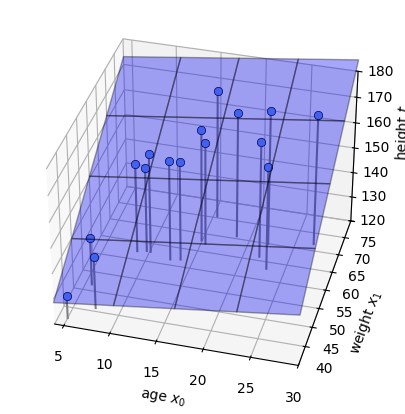

w0 = 0.4344965151347027, w1 = 1.116330809709452, w2 = 87.60608673858859


In [6]:
def show_data2(ax, x0, x1, t):
    for i in range(len(x0)):
        ax.plot(
            [x0[i], x0[i]],
            [x1[i], x1[i]],
            [120, t[i]],
            color='gray'
        )

    ax.plot(
        x0, x1, t,
        'o',
        color='cornflowerblue',
        markeredgecolor='black',
        markersize=6,
        markeredgewidth=0.5
    )

    ax.view_init(elev=35, azim=-75)


def show_plane(ax, w):
    # 그래프 표시용 범위: 실제 데이터가 축 밖으로 빠져 보이지 않도록 약간의 여백을 둔다.
    px0_min = min(X0_min, np.min(X0)) - 1
    px0_max = X0_max
    px1_min = min(X1_min, np.min(X1)) - 2
    px1_max = X1_max

    px0 = np.linspace(px0_min, px0_max, 5)
    px1 = np.linspace(px1_min, px1_max, 5)
    px0, px1 = np.meshgrid(px0, px1)
    y = predict_plane(px0, px1, w)

    ax.plot_surface(
        px0, px1, y,
        rstride=1,
        cstride=1,
        alpha=0.35,
        color='blue',
        edgecolor='black'
    )


print('반복횟수: {0}'.format(int(history[-1, 0])))
print('MSE = {0:.3f}, SD = {1:.3f}cm'.format(mse, sd))

fig = plt.figure(figsize=(6, 5))
ax = plt.subplot(1, 1, 1, projection='3d')
show_data2(ax, X0, X1, T)
show_plane(ax, W_gd)

ax.set_xlim(min(X0_min, np.min(X0)) - 1, X0_max)
ax.set_ylim(min(X1_min, np.min(X1)) - 2, X1_max)
ax.set_zlim(120, 180)
ax.set_xlabel('age $x_0$')
ax.set_ylabel('weight $x_1$')
ax.set_zlabel('height $t$')
plt.show()

print('w0 = {0}, w1 = {1}, w2 = {2}'.format(W_gd[0], W_gd[1], W_gd[2]))
